In [54]:
##  Task 2 — Load the official metadata into pandas
# In the first notebook cell, read the Food-101 split files and build one DataFrame per split with a resolved
# image path per row:

import pandas as pd
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data/food41"
IMG_DIR = DATA_DIR / "images"

classes = pd.read_csv(DATA_DIR/"meta/meta/classes.txt", header=None, names=["class"])
train_ids = pd.read_csv(DATA_DIR/"meta/meta/train.txt", header=None, names=["id"])
test_ids  = pd.read_csv(DATA_DIR/"meta/meta/test.txt", header=None, names=["id"])

def to_df(ids):
    df = ids.copy()
    df["class"] = df["id"].str.split("/").str[0]
    df["path"] = df["id"].apply(lambda x: IMG_DIR / f"{x}.jpg")
    return df

train_df = to_df(train_ids)
test_df  = to_df(test_ids)
print(len(classes), len(train_df), len(test_df))
# This should print 90 67500 22500 — that's your sanity check that the metadata files match the spec's stated dataset size.


90 67500 22500


In [55]:
# Task 3 — Verify every file on disk actually exists
# The metadata says 101,000 images exist; confirm the files are really there before you analyze them:

train_df["exists"] = train_df["path"].apply(lambda p: p.exists())
test_df["exists"]  = test_df["path"].apply(lambda p: p.exists())
print("missing train:", (~train_df["exists"]).sum())
print("missing test:", (~test_df["exists"]).sum())
# Anything with exists == False goes on a "missing files" list — you'll need this list again in Task 6.

missing train: 0
missing test: 0


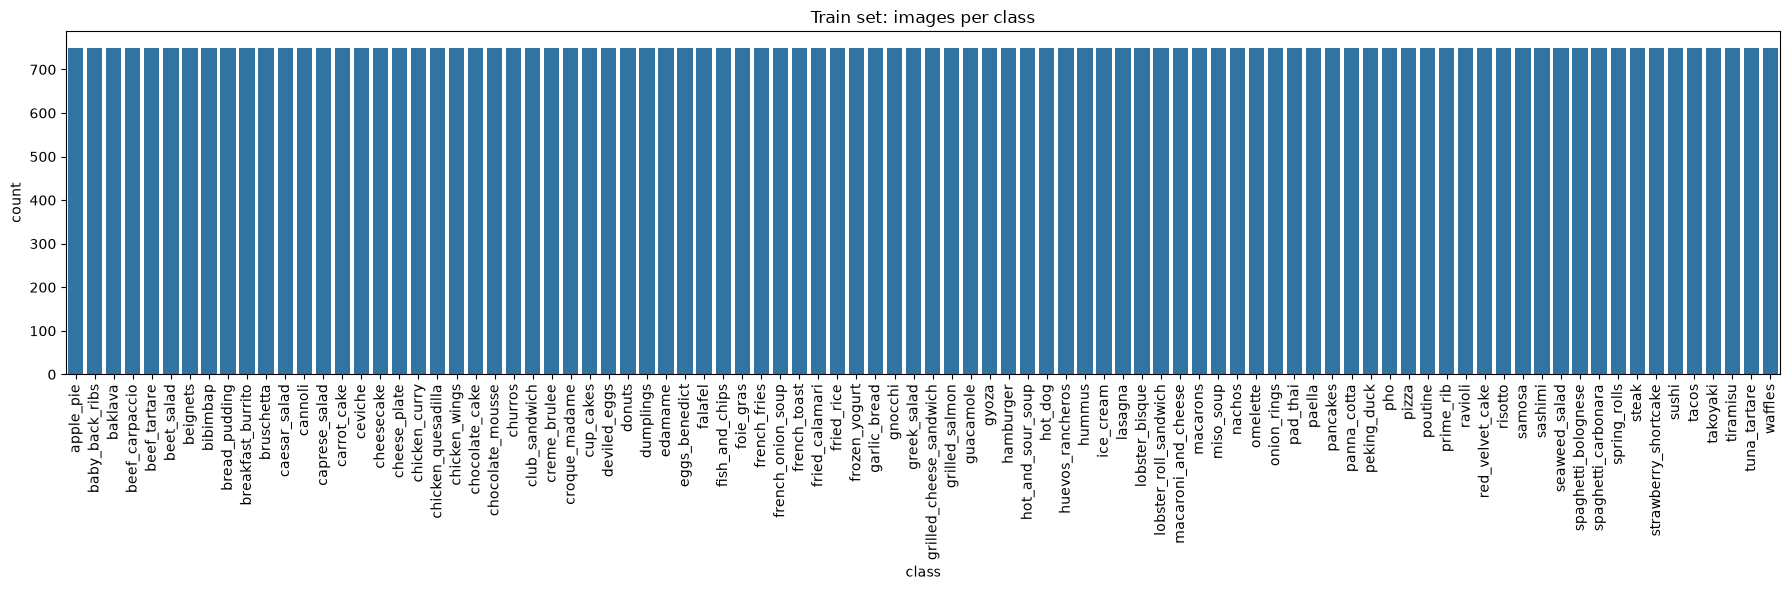

In [56]:
# Task 4 — Class distribution visualization (spec 2.4, required)
# This is one of the four explicitly required visualizations:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(18,6))
sns.countplot(data=train_df, x="class", order=classes["class"])
plt.xticks(rotation=90)
plt.title("Train set: images per class")
plt.tight_layout()
plt.show()

# Do the same for test_df. Formula/expectation to check against: Food-101 is designed as 750 train + 250 test images per class exactly.
# Your countplot bars should all be the same height — any class that deviates from 750/250 is a data issue to flag, not expected variance.


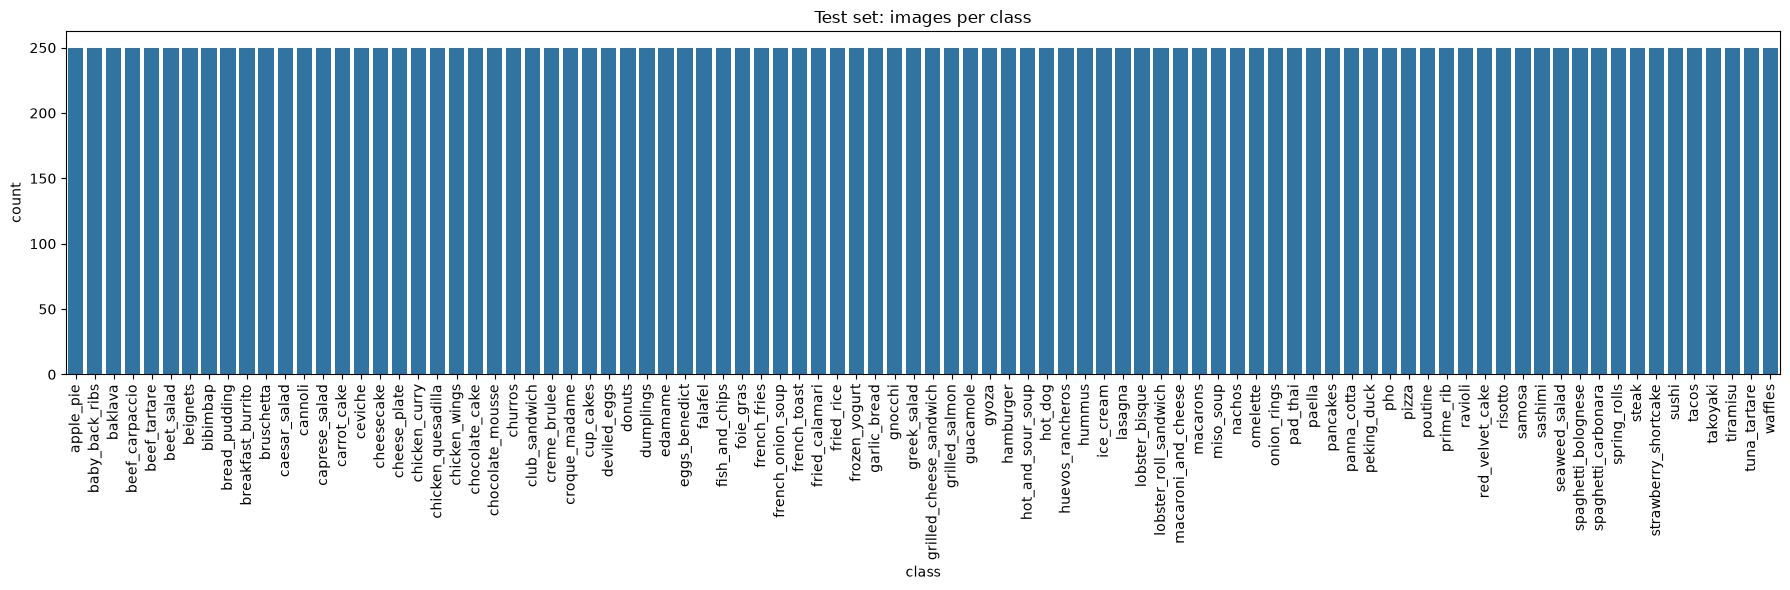

In [57]:
# Task 4 — Class distribution visualization (spec 2.4, required)
# This is one of the four explicitly required visualizations:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(18,6))
sns.countplot(data=test_df, x="class", order=classes["class"])
plt.xticks(rotation=90)
plt.title("Test set: images per class")
plt.tight_layout()
plt.show()

# Do the same for test_df. Formula/expectation to check against: Food-101 is designed as 750 train + 250 test images per class exactly.
# Your countplot bars should all be the same height — any class that deviates from 750/250 is a data issue to flag, not expected variance.


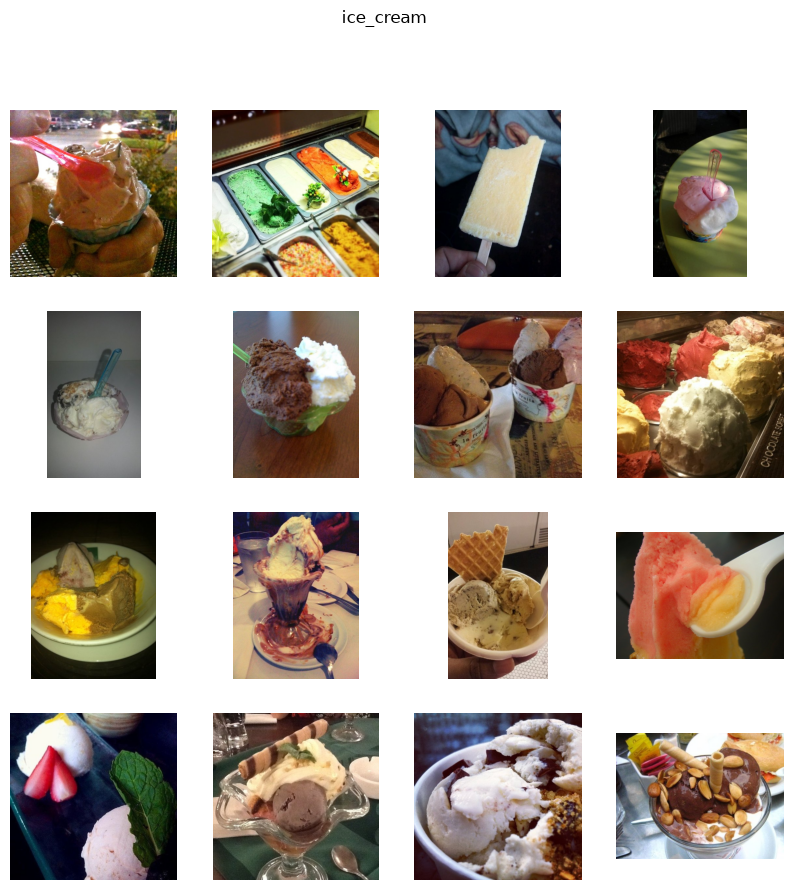

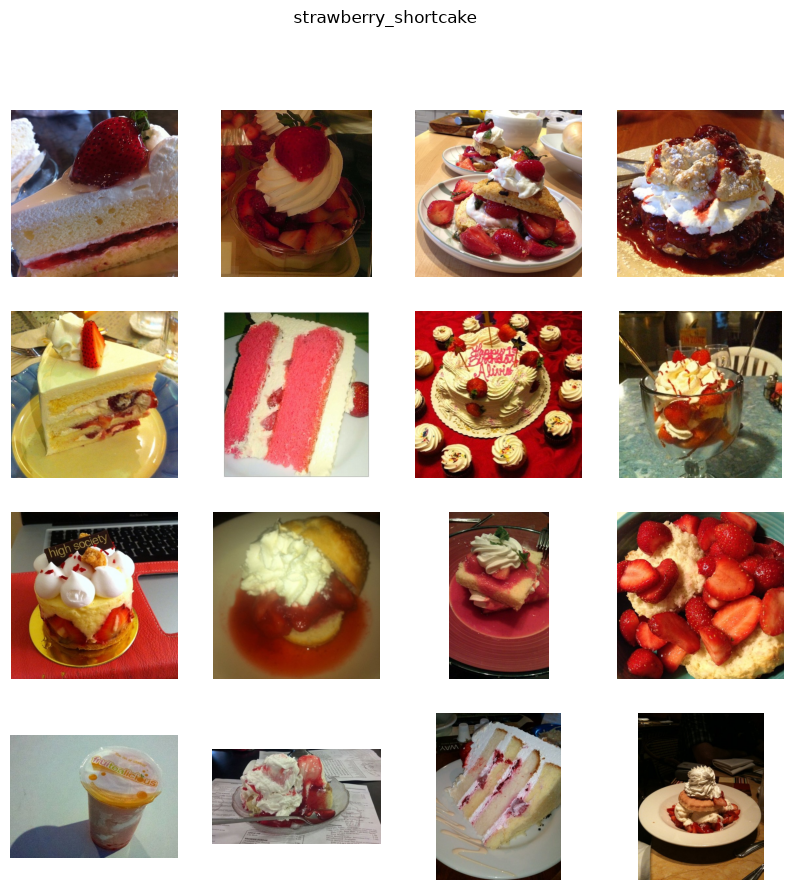

In [58]:
## Task 5 — Visual spot-check: sample grid per class
# Before any numeric cleaning, look at actual images. Pick ~5 classes and plot a 4x4 grid of random images from each:
import random
from PIL import Image

def show_grid(class_name, df, n=16):
    rows = df[df["class"] == class_name].sample(n)
    fig, axes = plt.subplots(4, 4, figsize=(10,10))
    for ax, path in zip(axes.flat, rows["path"]):
        ax.imshow(Image.open(path))
        ax.axis("off")
    fig.suptitle(class_name)
    plt.show()
      
show_grid("ice_cream", train_df)
show_grid("strawberry_shortcake", train_df)
  
# Look specifically for: mislabeled-looking images (spec's rice-vs-quinoa example), duplicated-looking photos,
# and obviously broken/blank frames. Note anything suspicious in a markdown cell — you'll act on it later,not now.


In [59]:
# Task 6 — Corrupted file detection
# Try to actually open every image with PIL and catch failures — this is the "corrupted files" bullet in spec 2.2:
from PIL import Image, UnidentifiedImageError

def check_corrupt(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except (UnidentifiedImageError, OSError):
        return False

train_df["is_valid"] = train_df["path"].apply(lambda p: check_corrupt(p) if p.exists() else False)
corrupted = train_df[~train_df["is_valid"]]
print(f"{len(corrupted)} corrupted/unreadable images")
corrupted.to_csv("corrupted_images.csv", index=False)

0 corrupted/unreadable images


<Axes: xlabel='min_dim', ylabel='Count'>

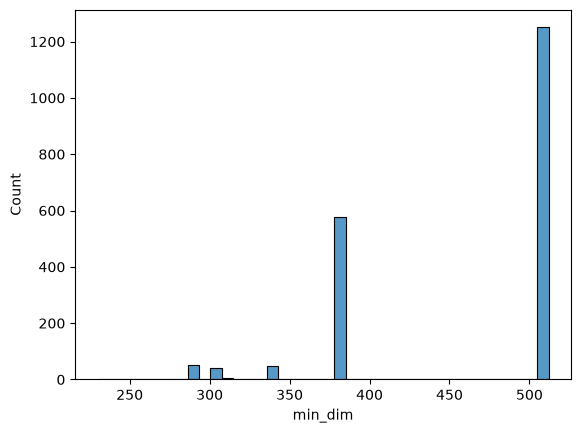

In [60]:
# Task 7 — Resolution distribution analysis
# The spec explicitly flags "images with too-low resolution" as a cleaning target. Measure it first:

def get_size(path):
    try:
        with Image.open(path) as im:
            return im.size  # (width, height)
    except Exception:
        return (None, None)
          
sample = train_df[train_df["path"].apply(lambda p: p.exists())].sample(2000, random_state=42)  # full 75k is slow; sample first
sample[["width","height"]] = sample["path"].apply(lambda p: pd.Series(get_size(p)))
sample["min_dim"] = sample[["width","height"]].min(axis=1)
sample["min_dim"].describe()
sns.histplot(sample["min_dim"], bins=40)
# Decide a threshold from what you see (e.g., anything below 128px on the short side is "too low resolution"
# for a 224x224 EfficientNet input) — write that threshold down, you'll need it for the actual cleaning step later.

In [61]:
# Task 8 — Near-blank / low-information image detection
# Spec 2.2 calls out fully black/white images specifically. Measure mean and standard deviation of pixel intensity — a near-blank image has std ≈ 0:
  
import numpy as np
  
def brightness_stats(path):
    try:
        with Image.open(path).convert("L") as im:
            arr = np.array(im)
        return arr.mean(), arr.std()
    except Exception:
        return (None, None)
          
sample[["mean_px","std_px"]] = sample["path"].apply(lambda p: pd.Series(brightness_stats(p)))
suspicious = sample[sample["std_px"] < 5]   # near-uniform image = likely blank
print(suspicious[["path","mean_px","std_px"]])
  
# std_px < 5 is a starting threshold — a real photo of food has texture and thus higher pixel variance; adjust
# after eyeballing a few flagged results.

Empty DataFrame
Columns: [path, mean_px, std_px]
Index: []


In [62]:
sample["std_px"].describe()
sample.nsmallest(5, "std_px")[["path","mean_px","std_px"]]

,path,mean_px,std_px
42550,/Users/bracha/plate-coach-vision/data/food41/i...,76.099106,15.644384
42338,/Users/bracha/plate-coach-vision/data/food41/i...,53.613293,16.500946
42686,/Users/bracha/plate-coach-vision/data/food41/i...,144.017010,21.514372
32884,/Users/bracha/plate-coach-vision/data/food41/i...,45.030685,22.446682
48818,/Users/bracha/plate-coach-vision/data/food41/i...,48.665165,22.739185


In [63]:
# Task 9 — Duplicate detection via perceptual hashing
# Spec 2.2 explicitly asks for this (Image Hashing / Perceptual Hash), to prevent train/test leakage:

import imagehash
def phash(path):
    try:
        return imagehash.phash(Image.open(path))
    except Exception:
        return None

sample["phash"] = sample["path"].apply(phash)

# Group images whose hashes are identical or near-identical (Hamming distance <= 5)
hashes = sample.dropna(subset=["phash"])[["path","phash"]].values
dupes = []
for i in range(len(hashes)):
    for j in range(i+1, len(hashes)):
        if hashes[i][1] - hashes[j][1] <= 5:  # Hamming distance
            dupes.append((hashes[i][0], hashes[j][0]))
print(f"{len(dupes)} near-duplicate pairs found in this sample")
# Note: a full 75k×75k comparison is O(n²) and too slow — this task is deliberately scoped to your 2000-image
# sample just to validate the method works. Scaling it to the full dataset (with a smarter approach, e.g.
# bucketing by hash prefix) is a separate, later task.


0 near-duplicate pairs found in this sample


In [64]:
# Task 10 — Write up a data-quality summary report
# Pull together everything from tasks 3, 6, 7, 8, 9 into one table — this becomes your decision document for
# the actual cleaning step (which comes after this, not part of these 10 tasks):
report = {
    "total_images_expected": len(classes)*1000,
    "missing_files": int((~train_df["exists"]).sum() + (~test_df["exists"]).sum()),
    "corrupted_files": len(corrupted),
    "low_resolution_sampled": int((sample["min_dim"] < 128).sum()),
    "near_blank_sampled": len(suspicious),
    "near_duplicate_pairs_sampled": len(dupes),
}
pd.Series(report).to_csv(PROJECT_ROOT / "notebooks" / "data_quality_report.csv")
report
# Add a markdown cell underneath summarizing, in your own words, what you saw in Task 5's visual spot-check
# (mislabeled candidates, anything odd) — that qualitative note plus this table is exactly the input you'll
# need for the real "Data Cleaning" step in spec section 2.2.


{'total_images_expected': 90000,
 'missing_files': 0,
 'corrupted_files': 0,
 'low_resolution_sampled': 0,
 'near_blank_sampled': 0,
 'near_duplicate_pairs_sampled': 0}